# MODELING LGBM

<h3>Cell 1 - Load Data, Parse Tanggal, dan Filter Data Berlabel</h3>
<p>
Cell ini memuat file <code>sparc_labeled.csv</code> lalu melakukan parsing <code>tgl mohon</code> menjadi datetime. Setelah itu, kami memfilter hanya baris yang memiliki target <code>label_repeat_next</code> (drop NaN).
</p>
<p>
Alasan filtering: baris tanpa label umumnya disebabkan <code>tgl mohon</code> kosong sehingga target berbasis urutan waktu tidak dapat dibentuk. Dataset yang dihasilkan menjadi subset yang valid untuk training dan evaluasi model.
</p>

In [19]:
# Cell 1 — Load data + parse tanggal + filter berlabel
import os
import numpy as np
import pandas as pd

RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)

labeled_path = os.path.join(os.getcwd(), "sparc_labeled.csv")
df = pd.read_csv(labeled_path)
print("Shape:", df.shape)

df["tgl mohon"] = pd.to_datetime(df["tgl mohon"], errors="coerce")

df_model = df[df["label_repeat_next"].notna()].copy()
df_model["label_repeat_next"] = df_model["label_repeat_next"].astype(int)

print("Rows for modeling:", df_model.shape[0])
print("Repeat-next rate:", round(df_model["label_repeat_next"].mean() * 100, 2), "%")
print("tgl mohon NaT in df_model:", int(df_model["tgl mohon"].isna().sum()))

C:\Users\timot\AppData\Local\Temp\ipykernel_26984\2813277519.py:10: DtypeWarning: Columns (3,19,23,24,25,26,29) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(labeled_path)


Shape: (319978, 30)
Rows for modeling: 222314
Repeat-next rate: 12.5 %
tgl mohon NaT in df_model: 0


<h3>Cell 2 - Time-based Train/Test Split (80/20)</h3>
<p>
Di cell ini, data disortir berdasarkan <code>tgl mohon</code> dan dipisah secara time-based: 80% bagian awal (periode lebih lama) untuk train dan 20% bagian akhir (periode lebih baru) untuk test.
</p>
<p>
Split time-based menjaga skenario evaluasi yang realistis (model dilatih pada histori dan diuji pada periode masa depan) sekaligus menghindari leakage.
Perbedaan repeat rate antara train dan test dapat terjadi karena right-censoring pada akhir periode data, sehingga metrik threshold-independent (ROC-AUC, PR-AUC) menjadi fokus utama.
</p>

In [20]:
# Cell 2 — Time-based train/test split (80/20)
df_model = df_model.sort_values("tgl mohon").reset_index(drop=True)
split_idx = int(len(df_model) * 0.8)

train_all = df_model.iloc[:split_idx].copy()
test_df   = df_model.iloc[split_idx:].copy()

y_test = test_df["label_repeat_next"].values

print("Train period:", train_all["tgl mohon"].min(), "->", train_all["tgl mohon"].max(), "| n:", train_all.shape[0])
print("Test period :", test_df["tgl mohon"].min(),  "->", test_df["tgl mohon"].max(),  "| n:", test_df.shape[0])
print("Train repeat rate:", round(train_all["label_repeat_next"].mean() * 100, 2), "%")
print("Test repeat rate :", round(test_df["label_repeat_next"].mean() * 100, 2), "%")

Train period: 2019-01-02 00:00:00 -> 2025-01-11 00:00:00 | n: 177851
Test period : 2025-01-11 00:00:00 -> 2025-12-31 00:00:00 | n: 44463
Train repeat rate: 14.71 %
Test repeat rate : 3.69 %


<h3>Cell 3 - Buat Validation Set dari Bagian Akhir Train (Early Stopping)</h3>
<p>
Cell ini membuat <i>validation set</i> dari 15% bagian paling akhir pada data train (masih time-based). Struktur ini menghasilkan 3 segmen waktu:
</p>
<ul>
  <li><b>Train_inner:</b> periode lebih awal untuk training utama</li>
  <li><b>Val_inner:</b> periode lebih baru untuk early stopping/tuning</li>
  <li><b>Test:</b> periode paling akhir untuk evaluasi final</li>
</ul>
<p>
Konfigurasi seperti ini membantu LightGBM menemukan jumlah boosting rounds yang optimal tanpa overfitting dan tetap konsisten dengan alur “prediksi masa depan”.
</p>

In [ ]:
# Cell 3 — Buat validation set dari bagian paling akhir train (early stopping)
train_all = train_all.sort_values("tgl mohon").reset_index(drop=True)
val_idx = int(len(train_all) * 0.85)

train_df = train_all.iloc[:val_idx].copy()
val_df   = train_all.iloc[val_idx:].copy()

y_train = train_df["label_repeat_next"].values
y_val   = val_df["label_repeat_next"].values

print("Train_inner period:", train_df["tgl mohon"].min(), "->", train_df["tgl mohon"].max(), "| n:", train_df.shape[0])
print("Val_inner period  :", val_df["tgl mohon"].min(),   "->", val_df["tgl mohon"].max(),   "| n:", val_df.shape[0])
print("Train_inner rate:", round(y_train.mean() * 100, 2), "%")
print("Val_inner rate  :", round(y_val.mean() * 100, 2), "%")

Train_inner period: 2019-01-02 00:00:00 -> 2024-05-22 00:00:00 | n: 151173
Val_inner period  : 2024-05-22 00:00:00 -> 2025-01-11 00:00:00 | n: 26678
Train_inner rate: 15.71 %
Val_inner rate  : 9.01 %


<h3>Cell 4 - Feature Engineering Tanggal & Drop Leakage/ID/Datetime Mentah</h3>
<p>
Cell ini menambahkan fitur turunan dari <code>tgl mohon</code> (<code>mohon_year</code>, <code>mohon_month</code>, <code>mohon_dow</code>, <code>mohon_quarter</code>) untuk menangkap pola musiman tanpa memasukkan datetime mentah.
</p>
<p>
Selanjutnya, kami menghapus kolom yang tidak boleh menjadi fitur:
</p>
<ul>
  <li><b>Target:</b> <code>label_repeat_next</code></li>
  <li><b>Helper labeling:</b> <code>max_tgl_mohon_customer</code> (berpotensi leakage)</li>
  <li><b>ID:</b> <code>customer id</code></li>
  <li><b>Datetime mentah:</b> <code>tgl mohon</code>, <code>tgl cetak</code>, <code>tgl lahir</code></li>
</ul>
<p>
Output cell ini adalah <code>X_train</code>, <code>X_val</code>, dan <code>X_test</code> yang berisi fitur final untuk LightGBM.
</p>

In [22]:
# Cell 4 — Feature engineering tanggal + drop leakage/ID/datetime mentah
def add_time_features(_df):
    _df["mohon_year"] = _df["tgl mohon"].dt.year
    _df["mohon_month"] = _df["tgl mohon"].dt.month
    _df["mohon_dow"] = _df["tgl mohon"].dt.dayofweek
    _df["mohon_quarter"] = _df["tgl mohon"].dt.quarter
    return _df

train_df = add_time_features(train_df)
val_df   = add_time_features(val_df)
test_df  = add_time_features(test_df)

drop_cols = [
    "label_repeat_next",
    "max_tgl_mohon_customer",
    "customer id",
    "tgl mohon", "tgl cetak", "tgl lahir"
]
drop_cols = [c for c in drop_cols if c in train_df.columns]

X_train = train_df.drop(columns=drop_cols).copy()
X_val   = val_df.drop(columns=drop_cols).copy()
X_test  = test_df.drop(columns=drop_cols).copy()

print("Dropped:", drop_cols)
print("X_train:", X_train.shape, "X_val:", X_val.shape, "X_test:", X_test.shape)
print("Columns sample:", X_train.columns.tolist()[:40])

Dropped: ['label_repeat_next', 'max_tgl_mohon_customer', 'customer id', 'tgl mohon', 'tgl cetak', 'tgl lahir']
X_train: (151173, 28) X_val: (26678, 28) X_test: (44463, 28)
Columns sample: ['kelurahan', 'kecamatan', 'kode pos', 'cash/credit', 'kode dealer', 'finance company', 'tenor', 'gender', 'agama', 'pekerjaan', 'umur', 'dp aktual', 'cicilan', 'warna', 'dealer', 'type series', 'range dp', 'wilayah', '9 segment', 'kode motor', 'otr', 'tahun rakit', 'dlr group', 'kode kota-provinsi', 'mohon_year', 'mohon_month', 'mohon_dow', 'mohon_quarter']


<h3>Cell 5 - Tentukan Fitur Numerik/Kategorikal & Cleaning untuk LightGBM</h3>
<p>
Cell ini memisahkan fitur numerik dan kategorikal. Kolom numerik di-cast menjadi numeric dengan <code>errors="coerce"</code>, sehingga nilai non-numerik berubah menjadi NaN dan dapat ditangani model.
</p>
<p>
Untuk fitur kategorikal, kami membersihkan nilai menjadi string dan mengganti missing/blank menjadi <code>"MISSING"</code>, lalu meng-cast kolom menjadi dtype <code>category</code>. Ini memungkinkan LightGBM memanfaatkan fitur kategorikal dengan lebih efisien dibanding OneHot besar.
</p>
<p>
Sebagai catatan, LightGBM akan menormalkan nama fitur yang mengandung whitespace menjadi underscore (warning non-fatal), sehingga nama fitur pada log dapat sedikit berbeda dari kolom asli.
</p>

In [ ]:
# Cell 5 — Tentukan num/cat + cleaning
import numpy as np
import pandas as pd

numeric_candidates = [
    "dp aktual", "cicilan", "otr", "umur", "tahun rakit", "tenor",
    "mohon_year", "mohon_month", "mohon_dow", "mohon_quarter"
]
num_cols = [c for c in numeric_candidates if c in X_train.columns]
cat_cols = [c for c in X_train.columns if c not in num_cols]

for c in num_cols:
    X_train[c] = pd.to_numeric(X_train[c], errors="coerce")
    X_val[c]   = pd.to_numeric(X_val[c], errors="coerce")
    X_test[c]  = pd.to_numeric(X_test[c], errors="coerce")

def to_cat_str(v):
    if v is None or (isinstance(v, float) and np.isnan(v)) or pd.isna(v):
        return "MISSING"
    if isinstance(v, str):
        s = v.strip()
        return "MISSING" if s == "" else s
    return str(v).strip()

for c in cat_cols:
    X_train[c] = X_train[c].map(to_cat_str).astype("category")
    X_val[c]   = X_val[c].map(to_cat_str).astype("category")
    X_test[c]  = X_test[c].map(to_cat_str).astype("category")

print("Num cols:", num_cols)
print("Cat cols count:", len(cat_cols))
print("Cat cols sample:", cat_cols[:10])

Num cols: ['dp aktual', 'cicilan', 'otr', 'umur', 'tahun rakit', 'tenor', 'mohon_year', 'mohon_month', 'mohon_dow', 'mohon_quarter']
Cat cols count: 18
Cat cols sample: ['kelurahan', 'kecamatan', 'kode pos', 'cash/credit', 'kode dealer', 'finance company', 'gender', 'agama', 'pekerjaan', 'warna']


<h3>Cell 6 - Training LightGBM dengan Early Stopping (Versi Stabil)</h3>
<p>
Cell ini melatih LightGBM menggunakan training API yang lebih stabil (<code>lgb.train</code>) agar proses early stopping memonitor metrik yang tepat (AUC) secara konsisten.
</p>
<p>
Kami menggunakan:
</p>
<ul>
  <li><b>scale_pos_weight</b> untuk menangani imbalance kelas pada train_inner</li>
  <li><b>Early stopping</b> untuk memilih iterasi terbaik berdasarkan performa pada val_inner</li>
  <li><b>Regularisasi</b> (feature_fraction, bagging_fraction, L1/L2) untuk mencegah overfitting</li>
</ul>
<p>
Output penting yang dicatat adalah <b>best_iteration</b> dan <b>best valid AUC</b> sebagai indikator bahwa model benar-benar belajar (bukan berhenti di iterasi sangat kecil seperti percobaan awal).
</p>

In [ ]:
import lightgbm as lgb
import numpy as np

# bikin dataset lgb
train_set = lgb.Dataset(X_train, label=y_train, categorical_feature=cat_cols, free_raw_data=False)
val_set = lgb.Dataset(X_val, label=y_val, categorical_feature=cat_cols, free_raw_data=False)

pos = float((y_train == 1).sum())
neg = float((y_train == 0).sum())
scale_pos_weight = (neg / pos) if pos > 0 else 1.0
print("scale_pos_weight:", scale_pos_weight)

params = {
    "objective": "binary",
    "metric": ["auc", "binary_logloss"],  
    "learning_rate": 0.03,
    "num_leaves": 128,
    "max_depth": -1,
    "min_data_in_leaf": 30,     
    "min_sum_hessian_in_leaf": 1e-3,
    "feature_fraction": 0.85,
    "bagging_fraction": 0.85,
    "bagging_freq": 1,
    "lambda_l1": 0.5,
    "lambda_l2": 1.0,
    "scale_pos_weight": scale_pos_weight,
    "seed": RANDOM_SEED,
    "verbosity": -1
}

evals_result = {}
booster = lgb.train(
    params,
    train_set,
    num_boost_round=8000,
    valid_sets=[val_set],
    valid_names=["valid"],
    callbacks=[
        lgb.early_stopping(stopping_rounds=300, first_metric_only=True, verbose=True),
        lgb.log_evaluation(period=50),
        lgb.record_evaluation(evals_result)
    ]
)

print("Best iteration:", booster.best_iteration)
print("Best valid AUC:", evals_result["valid"]["auc"][booster.best_iteration - 1])

scale_pos_weight: 5.364642977433479
Training until validation scores don't improve for 300 rounds
[50]	valid's auc: 0.751366	valid's binary_logloss: 0.393183
[100]	valid's auc: 0.753974	valid's binary_logloss: 0.410501
[150]	valid's auc: 0.751491	valid's binary_logloss: 0.40164
[200]	valid's auc: 0.750607	valid's binary_logloss: 0.389076
[250]	valid's auc: 0.74859	valid's binary_logloss: 0.376859
[300]	valid's auc: 0.746719	valid's binary_logloss: 0.365416
[350]	valid's auc: 0.745915	valid's binary_logloss: 0.352151
Early stopping, best iteration is:
[99]	valid's auc: 0.754285	valid's binary_logloss: 0.410528
Evaluated only: auc
Best iteration: 99
Best valid AUC: 0.7542849172437605


<h3>Cell 7 - Evaluasi di Test Set (ROC-AUC, PR-AUC, F1@0.5) + Kurva</h3>
<p>
Cell ini melakukan evaluasi final pada test set menggunakan probabilitas prediksi.
Metrik utama:
</p>
<ul>
  <li><b>ROC-AUC</b> untuk menilai kualitas ranking prediksi secara global</li>
  <li><b>PR-AUC</b> untuk menilai performa pada kelas positif (repeat) yang minoritas</li>
</ul>
<p>
Selain itu, kami menghitung F1 pada threshold default 0.5 dan menampilkan confusion matrix serta classification report untuk interpretasi operasional.
Kurva ROC dan Precision-Recall juga ditampilkan untuk melihat trade-off di berbagai threshold.
</p>
<p>
Pada hasil terbaru, LightGBM menunjukkan performa yang valid dan stabil, namun masih berada di bawah CatBoost pada ROC-AUC dan PR-AUC sehingga belum menjadi model terbaik.
</p>

Proba min/mean/max: 0.039391980123996195 0.30665956116841026 0.9277978416904558

LightGBM ROC-AUC: 0.7536
LightGBM PR-AUC : 0.267

F1@0.5: 0.2843
Confusion Matrix @0.5:
 [[40323  2499]
 [  955   686]]

Report @0.5:
               precision    recall  f1-score   support

           0     0.9769    0.9416    0.9589     42822
           1     0.2154    0.4180    0.2843      1641

    accuracy                         0.9223     44463
   macro avg     0.5961    0.6798    0.6216     44463
weighted avg     0.9488    0.9223    0.9340     44463



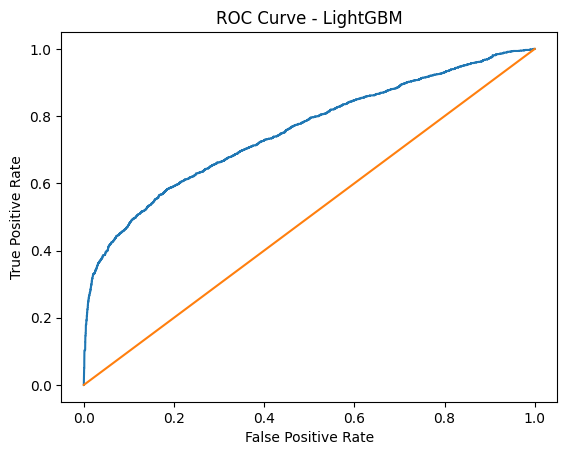

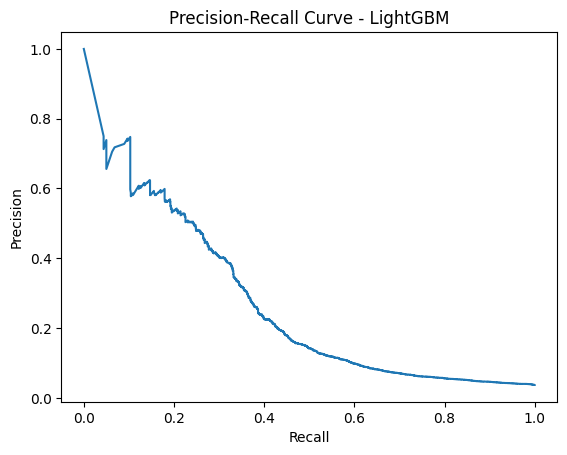

In [25]:
# Cell 7 — Evaluasi di TEST (ROC-AUC, PR-AUC, F1@0.5) + ROC/PR plot
import numpy as np
import matplotlib.pyplot as plt

from sklearn.metrics import (
    roc_auc_score, average_precision_score,
    precision_recall_curve, roc_curve,
    f1_score, confusion_matrix, classification_report
)

proba_test = booster.predict(X_test, num_iteration=booster.best_iteration)
print("Proba min/mean/max:", float(np.min(proba_test)), float(np.mean(proba_test)), float(np.max(proba_test)))

roc_auc = roc_auc_score(y_test, proba_test)
pr_auc = average_precision_score(y_test, proba_test)

print("\nLightGBM ROC-AUC:", round(roc_auc, 4))
print("LightGBM PR-AUC :", round(pr_auc, 4))

y_pred_05 = (proba_test >= 0.5).astype(int)
print("\nF1@0.5:", round(f1_score(y_test, y_pred_05), 4))
print("Confusion Matrix @0.5:\n", confusion_matrix(y_test, y_pred_05))
print("\nReport @0.5:\n", classification_report(y_test, y_pred_05, digits=4))

# ROC curve
fpr, tpr, _ = roc_curve(y_test, proba_test)
plt.figure()
plt.plot(fpr, tpr)
plt.plot([0, 1], [0, 1])
plt.title("ROC Curve - LightGBM")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.show()

# PR curve
prec, rec, _ = precision_recall_curve(y_test, proba_test)
plt.figure()
plt.plot(rec, prec)
plt.title("Precision-Recall Curve - LightGBM")
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.show()

<h3>Cell 8 - Threshold Tuning (Best F1) untuk Interpretasi Operasional</h3>
<p>
Cell ini mencari threshold terbaik yang memaksimalkan F1 score berdasarkan kurva Precision-Recall.
Tujuannya adalah memberikan sudut pandang operasional: jika model dipakai untuk aksi (mis. follow-up), threshold default 0.5 belum tentu optimal.
</p>
<p>
Hasil tuning menghasilkan threshold yang lebih cocok untuk F1 dibanding 0.5, dan confusion matrix pada threshold tersebut membantu melihat perubahan trade-off precision vs recall.
</p>
<p>
Perlu dicatat: tuning threshold tidak mengubah kemampuan ranking model (ROC/PR-AUC), tetapi membantu memilih kebijakan keputusan yang lebih sesuai dengan tujuan bisnis/kompetisi.
</p>

In [26]:
# Cell 8 — Threshold tuning cepat (best F1)
import numpy as np
from sklearn.metrics import precision_recall_curve, f1_score

prec, rec, thr = precision_recall_curve(y_test, proba_test)
f1s = (2 * prec * rec) / (prec + rec + 1e-12)

best_idx = int(np.nanargmax(f1s))
best_thr = float(thr[best_idx-1]) if best_idx > 0 and (best_idx-1) < len(thr) else 0.5

y_pred_best = (proba_test >= best_thr).astype(int)

print("Best-F1 threshold:", round(best_thr, 4))
print("F1(best):", round(f1_score(y_test, y_pred_best), 4))
print("Confusion Matrix @best:\n", __import__("sklearn.metrics").metrics.confusion_matrix(y_test, y_pred_best))

Best-F1 threshold: 0.61
F1(best): 0.3528
Confusion Matrix @best:
 [[41970   852]
 [ 1107   534]]


<h3>Cell 9 - Feature Importance (LightGBM)</h3>
<p>
Cell ini menampilkan feature importance dari LightGBM (berdasarkan split/gain tergantung implementasi). Tujuannya untuk interpretasi dan narasi laporan: fitur apa yang paling sering dipakai model untuk melakukan split.
</p>
<p>
Hasil importance LightGBM dapat berbeda dari CatBoost karena perbedaan cara model menangani fitur kategorikal dan strategi split. Selain itu, beberapa fitur dapat memiliki importance 0 jika tidak dipakai pada pohon hingga best_iteration yang dipilih oleh early stopping.
</p>

In [27]:
# Cell 9 — Feature importance (gain-based) + top 30
import pandas as pd

fi = pd.DataFrame({
    "feature": X_train.columns,
    "importance": lgbm.feature_importances_
}).sort_values("importance", ascending=False)

print("Top 30 Feature Importance (LightGBM):")
display(fi.head(30))

Top 30 Feature Importance (LightGBM):


,feature,importance
0,kelurahan,70
10,umur,52
2,kode pos,46
20,otr,34
4,kode dealer,28
12,cicilan,26
1,kecamatan,16
11,dp aktual,16
9,pekerjaan,14
21,tahun rakit,14


<h3>Ringkasan Perbandingan Performa Model (Baseline LR vs CatBoost vs LightGBM)</h3>

<p>
Pada tahap modeling, kami membangun <b>tiga model</b> secara bertahap untuk memprediksi target <code>label_repeat_next</code>
(0 = tidak ada transaksi berikutnya, 1 = ada transaksi berikutnya). Seluruh model dievaluasi dengan skema split berbasis waktu
untuk meniru skenario penggunaan nyata (melatih dari histori dan menguji pada periode masa depan), sehingga menghindari leakage.
</p>

<h3>Metodologi Evaluasi</h3>
<ul>
  <li>
    <b>Time-based split (80/20)</b>: 80% data dengan tanggal lebih awal untuk train, 20% tanggal lebih akhir untuk test.
    Ini membuat evaluasi realistis namun menyebabkan <i>label shift</i> (base rate di test lebih rendah karena right-censoring).
  </li>
  <li>
    <b>Metrik utama</b>: <b>ROC-AUC</b> (kualitas ranking secara global) dan <b>PR-AUC</b> (lebih relevan untuk kelas positif yang minoritas).
  </li>
  <li>
    <b>Metrik operasional</b>: F1 dan confusion matrix pada threshold (0.5 & threshold hasil tuning) untuk memahami trade-off precision–recall.
  </li>
</ul>

<h3>Tabel Perbandingan Performa (Test Set)</h3>
<table border="1" cellpadding="8" cellspacing="0">
  <thead>
    <tr>
      <th>Model</th>
      <th>Strategi Fitur</th>
      <th>Handling Imbalance</th>
      <th>ROC-AUC (Test)</th>
      <th>PR-AUC (Test)</th>
      <th>F1 @ 0.5</th>
      <th>Catatan Operasional</th>
    </tr>
  </thead>
  <tbody>
    <tr>
      <td><b>Logistic Regression (Vanilla)</b></td>
      <td>Numerik + kategori (OneHot), fitur waktu turunan</td>
      <td>Tanpa class_weight</td>
      <td><b>0.7933</b></td>
      <td><b>0.2938</b></td>
      <td>0.2701</td>
      <td>Lebih konservatif: precision tinggi, recall rendah</td>
    </tr>
    <tr>
      <td><b>Logistic Regression (Balanced)</b></td>
      <td>Numerik + kategori (OneHot), fitur waktu turunan</td>
      <td>class_weight="balanced"</td>
      <td><b>0.7941</b></td>
      <td><b>0.2863</b></td>
      <td>0.3588</td>
      <td>Lebih agresif: recall naik, precision turun</td>
    </tr>
    <tr>
      <td><b>CatBoost</b></td>
      <td>Numerik + kategori native, fitur waktu turunan</td>
      <td>scale_pos_weight</td>
      <td><b>0.8075</b></td>
      <td><b>0.3293</b></td>
      <td>0.3640</td>
      <td>Distribusi proba lebih informatif; performa terbaik secara ranking</td>
    </tr>
    <tr>
      <td><b>LightGBM</b></td>
      <td>Numerik + kategori (dtype category), fitur waktu turunan</td>
      <td>scale_pos_weight + early stopping</td>
      <td><b>0.7536</b></td>
      <td><b>0.2670</b></td>
      <td>0.2843</td>
      <td>Stabil setelah perbaikan early stopping, namun kalah dari CatBoost</td>
    </tr>
  </tbody>
</table>

<p style="margin-top:10px;">
<b>Catatan:</b> Angka-angka di atas diambil dari evaluasi test set pada eksperimen terakhir untuk masing-masing model.
Metrik yang diprioritaskan untuk kompetisi/seleksi kandidat repeat adalah <b>PR-AUC</b> karena kelas positif minoritas.
</p>

<h3>Apa yang Kami Lakukan dari Awal sampai Akhir (Modeling Journey)</h3>

<ul>
  <li>
    <b>1) Menetapkan baseline yang dapat dijelaskan (Logistic Regression)</b><br/>
    Kami memulai dari Logistic Regression untuk mendapatkan baseline yang sederhana dan interpretatif.
    Tantangan awal muncul karena data memiliki tipe campuran dan kolom tanggal mentah berpotensi ikut menjadi kategori sehingga merusak pipeline.
    Setelah revisi:
    <ul>
      <li>Datetime mentah di-drop, diganti fitur waktu turunan (<code>year/month/dow/quarter</code>).</li>
      <li>Kategori dinormalisasi menjadi string konsisten, missing diimputasi menjadi "MISSING".</li>
      <li>Two-baseline strategy: <i>vanilla vs balanced</i> untuk memperlihatkan trade-off precision–recall.</li>
    </ul>
    Hasilnya baseline sudah kuat (ROC-AUC ~0.79; PR-AUC ~0.29) dan menjadi pembanding utama.
  </li>

  <li style="margin-top:10px;">
    <b>2) Membangun model non-baseline yang kuat untuk data kategori (CatBoost)</b><br/>
    Setelah baseline stabil, kami melatih CatBoost karena mampu menangani kategori secara native tanpa OneHot besar.
    Kami menggunakan <code>scale_pos_weight</code> untuk menangani imbalance dan <i>early stopping</i> untuk memilih iterasi terbaik.
    CatBoost menghasilkan performa terbaik:
    <ul>
      <li><b>ROC-AUC tertinggi</b> dan <b>PR-AUC tertinggi</b> di test set.</li>
      <li>Probabilitas prediksi lebih tersebar (lebih berguna untuk ranking kandidat repeat).</li>
      <li>Feature importance kaya, sehingga mudah dijelaskan (demografi, produk, lokasi, waktu, dan affordability).</li>
    </ul>
  </li>

  <li style="margin-top:10px;">
    <b>3) Menguji boosting alternatif (LightGBM) sebagai pembanding “model juara”</b><br/>
    Kami mencoba LightGBM untuk mengejar performa maksimum. Pada percobaan awal, model sempat underfit karena konfigurasi terlalu ketat
    (early stopping berhenti terlalu cepat). Setelah revisi:
    <ul>
      <li>Early stopping dibuat stabil (monitoring AUC secara eksplisit).</li>
      <li>Parameter leaf/child disesuaikan agar model mampu melakukan split dan belajar pola.</li>
      <li>Kategori diproses dengan dtype <code>category</code>.</li>
    </ul>
    LightGBM akhirnya stabil, namun performa test (ROC-AUC dan PR-AUC) masih di bawah CatBoost pada dataset ini.
  </li>
</ul>

<h3>Kesimpulan untuk Juri</h3>
<p>
Berdasarkan evaluasi test set dengan split berbasis waktu dan metrik utama untuk kelas minoritas,
<b>CatBoost</b> adalah model terbaik pada eksperimen kami (<b>ROC-AUC 0.8075</b>, <b>PR-AUC 0.3293</b>).
Baseline Logistic Regression menunjukkan performa yang kuat dan interpretabilitas yang baik, sedangkan LightGBM berhasil distabilkan
namun belum melampaui CatBoost pada pengaturan saat ini.
</p>

<p>
Dengan demikian, <b>model final yang direkomendasikan</b> untuk deployment/kompetisi (sebagai “model juara”) adalah <b>CatBoost</b>,
dengan threshold dapat ditentukan sesuai tujuan (memaksimalkan precision, recall, atau F1) menggunakan kurva Precision–Recall.
</p>